## Contents ##
1. [Deutsch-Jozsa Algorithm](#deutsch-jozsa-algorithm)
2. [Bernstein-Vazirani Algorithm](#bernstein-vazirani-algorithm)
3. [Quantum Phase Estimation](#quantum-phase-estimation)
4. [Grover's Search Algorithm](#grover's-algorithm)
5. [Simon's Algorithm](#simon's-problem)

In [ ]:

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator, StatevectorSimulator
from qiskit.circuit.library import QFT
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import random
import getpass
from itertools import combinations


In [145]:
%matplotlib inline

>Setting up the API token whilst keeping it secure and not expose it on a public repository.

In [167]:
# Paste your API token you copied from the IBM Quantum website

token = input("Enter your IBM Quantum API token: ")
from qiskit_ibm_runtime import QiskitRuntimeService 
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=token,   
    overwrite=True
)


## Deutsch-Jozsa Algorithm ##
>I defined my constant function as return 0 regardless of the input and my balanced function as return 1 if the first input is 1 (This gives an answer of 0 and 1 on half of the total possible input). Any other choice of functions could also have been chosen.


In [ ]:
def balanced(qc, n):
    qc.cx(0, n) #if first qubit is 1, flip the output qubit
    qc.barrier()

In [ ]:
def constant(qc, n):
    qc.barrier()
    return 

>I made my function to take in the number of qubits as a user-defined input. This gives the algorithm some flexibility however choosing a large value of n induces more noise when running on actual quantum harware. The function choice whether constant or balanced will be random and vary with each iteration. This can be easily changed to demonstrate both outputs however I am just keeping it random.

In [165]:
def build_dj_circuit(n):
    q = QuantumRegister(n+1)
    c = ClassicalRegister(n, name='c')
    qc = QuantumCircuit(q,c)

    qc.x(n)
    qc.h(range(n+1))
    qc.barrier()
    random_num = random.randint(0,1)
    if random_num == 0:
        constant(qc, n)
        print("Using constant function")
    else:
        balanced(qc, n)
        print("Using balanced function")
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc
    
def Deutsche_Jozsa_algorithm(qc, n, backend):
    print("Transpiling circuit...")
    compiled = transpile(qc, backend)

    sampler = SamplerV2(mode=backend)
    job = sampler.run([compiled], shots=1024)
    print(f"Job ID: {job.job_id()}")

    print("Waiting for job to complete...")
    result = job.result()
    pub_result = result[0]


    counts = pub_result.data.c.get_counts()

# --- PART 3: SHOW RESULTS ---
    print(f"Results from {backend.name}:")
    print("Counts:", counts)
    if('0'*n in counts and len(counts)==1):
        print("Function is constant")
    elif('0'*n in counts and len(counts)>1):
        if(counts['0'*n] > 512):
            print("Function is probably constant. Also got noise")
        else:
            print("Function is balanced. Maybe constant with noise")
    else:
        print("Function is balanced")


    return counts    


qiskit_runtime_service.__init__:WARNING:2025-11-16 16:22:22,009: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Using constant function


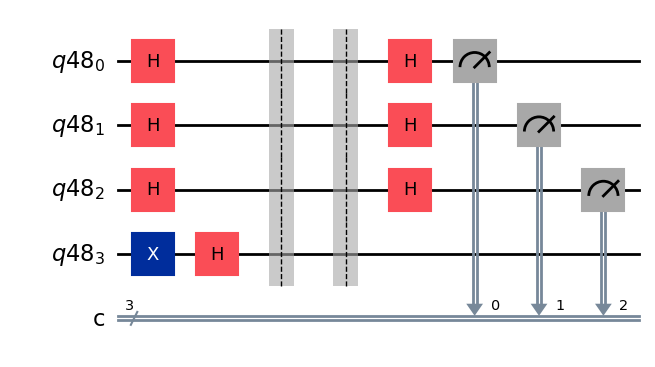

Transpiling circuit...
Job ID: 66defcf5-ca1e-4b7d-919a-202d1521f7ba
Waiting for job to complete...
Results from aer_simulator:
Counts: {'000': 1024}
Function is constant


qiskit_runtime_service.backends:WARNING:2025-11-16 16:22:22,863: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:22:26,091: Using instance: open-instance, plan: open


Transpiling circuit...
Job ID: d4cqprvnmdfs73af4840
Waiting for job to complete...
Results from ibm_fez:
Counts: {'000': 1023, '100': 1}
Function is probably constant. Also got noise


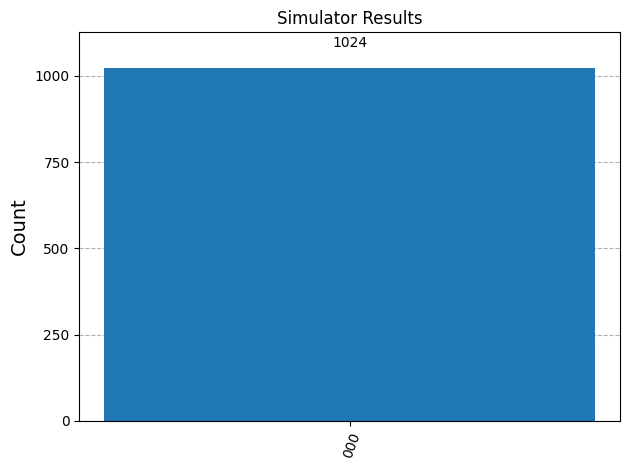

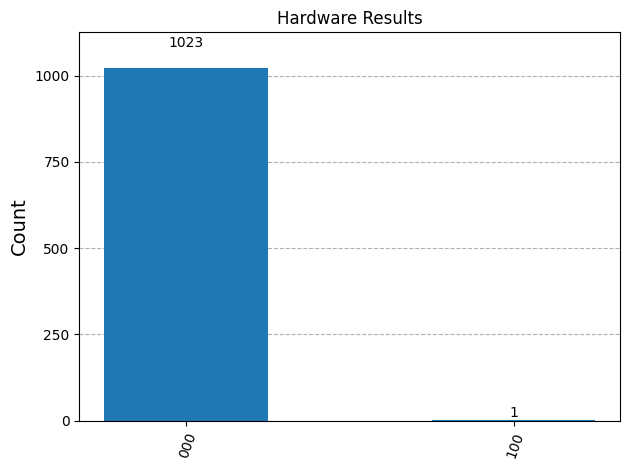

In [166]:
backend_sim =  AerSimulator()
service = QiskitRuntimeService(channel="ibm_quantum_platform")
n = 3  # Number of input qubits
circuit = build_dj_circuit(n)
circuit.draw(output = 'mpl')
plt.show()
sim_counts = Deutsche_Jozsa_algorithm(circuit, n, backend_sim)

backend_qpu = service.least_busy(simulator = False, operational = True)
qpu_counts = Deutsche_Jozsa_algorithm(circuit, n, backend_qpu)

if sim_counts:
    plot_histogram(sim_counts, title=f"Simulator Results")
if qpu_counts:
    plot_histogram(qpu_counts, title=f"Hardware Results")
plt.show()

>So our results on quantum harware are in close conjunction with what we observe on a classical simulator except a small amount of noise

## Bernstein-Vazirani Algorithm ##
>Input the choice of number of qubits and the code will randomly select a number from 0 to 2^(n-1). The oracle I am using does a CNOT wherever we encounter a 1 in the binary string format of the secret number. This closely represents the actual circuitry for the oracle we were taught in class.

In [ ]:
def Bernstein_vazirani_algorithm(n, backend):
    q = QuantumRegister(n+1)
    c = ClassicalRegister(n, name='c')
    qc = QuantumCircuit(q,c)

    qc.x(n)
    qc.h(range(n+1))
    random_num = random.randint(0,2**n - 1)
    print(f"Hidden number is: {random_num}")
    binary_num = format(random_num, f'0{n}b')
    for i in range(n):
        if binary_num[n-i-1] == '1':
            qc.cx(i, n)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    qc.draw(output = 'mpl')
    plt.show()

    print(f"Running on backend: {backend.name} ...")
    transpiled_qc = transpile(qc, backend)

    sampler = SamplerV2(mode=backend)
    job = sampler.run([transpiled_qc], shots=1024)
    print("Job ID: ", job.job_id())


    pub_result = job.result()[0]
    res = pub_result.data.c.get_counts()
    print("Bernstein-Vazirani Algorithm Result: ")
    print(res)
    
    if(binary_num in res and len(res)==1):
        print("Successfully found the hidden number!")
    elif(binary_num in res and len(res)>1):
        print("Probably found the hidden number. Also got noise")
    else:
        print("Did not find the hidden number.")

    return res

qiskit_runtime_service.__init__:WARNING:2025-11-16 16:20:16,318: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-11-16 16:20:17,005: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:20:20,371: Using instance: open-instance, plan: open


Backend selected: ibm_fez
Hidden number is: 20


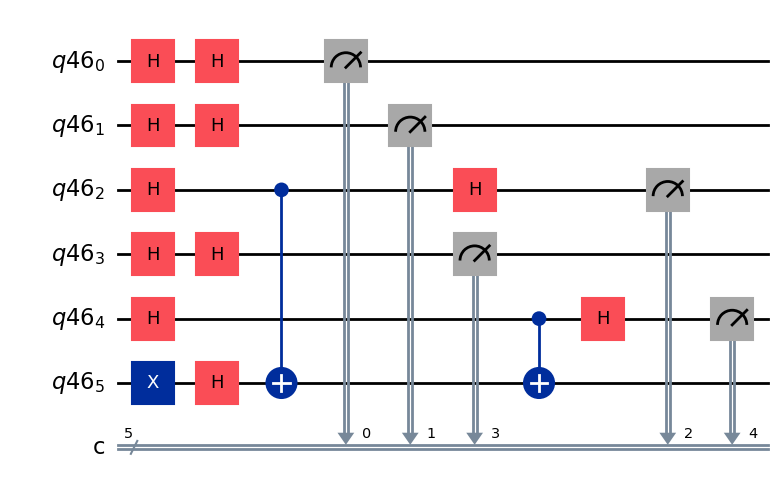

Running on backend: aer_simulator ...
Job ID:  dc4e9233-534e-4a95-93cf-30c3e8b5be5f
Bernstein-Vazirani Algorithm Result: 
{'10100': 1024}
Successfully found the hidden number!
Hidden number is: 23


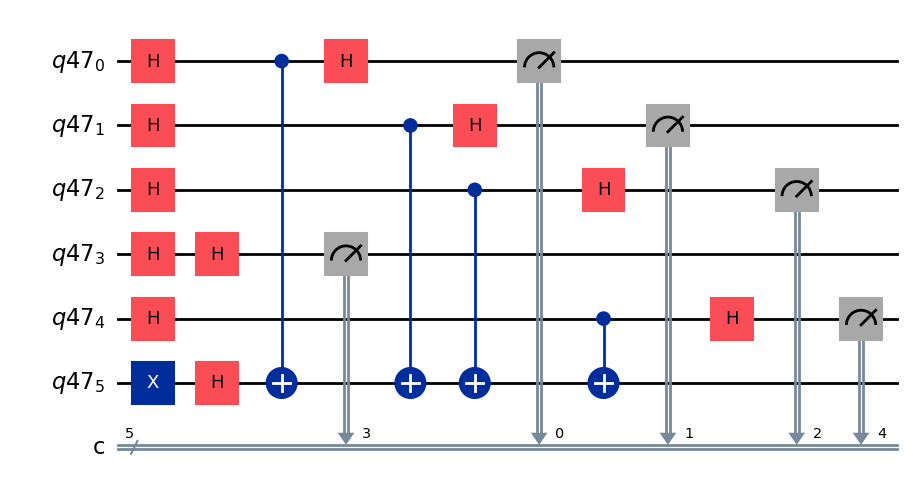

Running on backend: ibm_fez ...
Job ID:  d4cqossi51bc738k9so0
Bernstein-Vazirani Algorithm Result: 
{'10111': 891, '10011': 22, '00000': 3, '00110': 1, '10101': 28, '00111': 28, '10001': 11, '00101': 5, '10000': 5, '00011': 9, '00001': 3, '10110': 16, '10010': 1, '11111': 1}
Probably found the hidden number. Also got noise


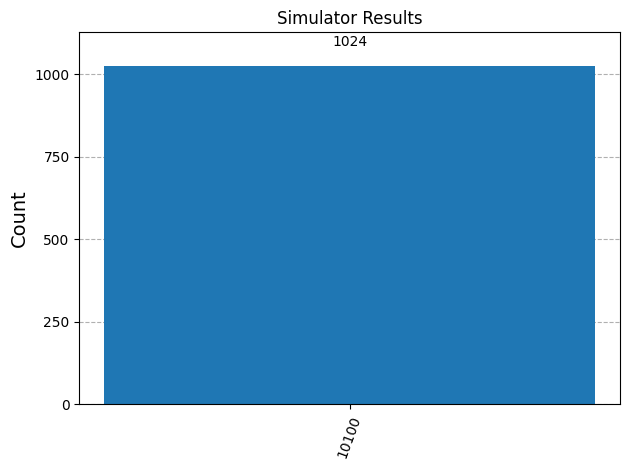

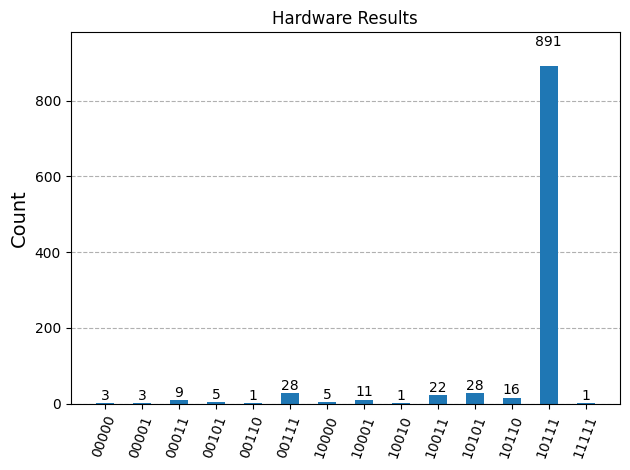

In [164]:
# 1. Connect to the service (this uses your saved account)
service = QiskitRuntimeService()
backend_sim = AerSimulator()
# 2. Find the least-busy REAL quantum device
backend = service.least_busy(simulator=False, operational=True)
print(f"Backend selected: {backend.name}")

sim_counts = Bernstein_vazirani_algorithm(5, backend_sim)
# 3. Transpile your circuit for that specific backend
qpu_counts = Bernstein_vazirani_algorithm(5, backend)

if sim_counts:
    plot_histogram(sim_counts, title=f"Simulator Results")
if qpu_counts:
    plot_histogram(qpu_counts, title=f"Hardware Results")
plt.show()

>We are again getting some noise in the quantum hardware along with the correct secret number in the binary representation

## Quantum-Phase Estimation ##
>For the U gates, I used an RZ gate with the specified angle. I directly used the inverse quantum fourier transform library. 

In [ ]:
PI = 3.141592653589793
def PhaseEstimation(t, phase, backend):
    q = QuantumRegister(t+1)
    c = ClassicalRegister(t, name='c')
    qc = QuantumCircuit(q,c)
    qc.h(range(t))
    qc.x(t)
    for i in range(t):
        qc.crz(phase*(2**i)*2*PI, i, t) #controlled phase rotation
    qft_circuit = QFT(t).inverse()
    qc.append(qft_circuit, range(t))
    qc.measure(range(t), range(t))
    qc.draw(output = 'mpl')
    plt.show()

    print(f"Running on backend: {backend.name} ...")
    transpiled_qc = transpile(qc, backend)

    sampler = SamplerV2(mode=backend)
    job = sampler.run([transpiled_qc], shots=1024)
    print("Job ID: ", job.job_id())
    print("Waiting for job to complete...")

    pub_result = job.result()[0]
    res = pub_result.data.c.get_counts()
    print("Phase Estimation Result: ")
    print(res)
    return res

    

>You can keep the phase you wish for. The code will guess it upto n bits.

qiskit_runtime_service.__init__:WARNING:2025-11-16 16:17:27,731: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Backend selected: aer_simulator


C:\Users\shahv\AppData\Local\Temp\ipykernel_29408\592573372.py:10: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_circuit = QFT(t).inverse()


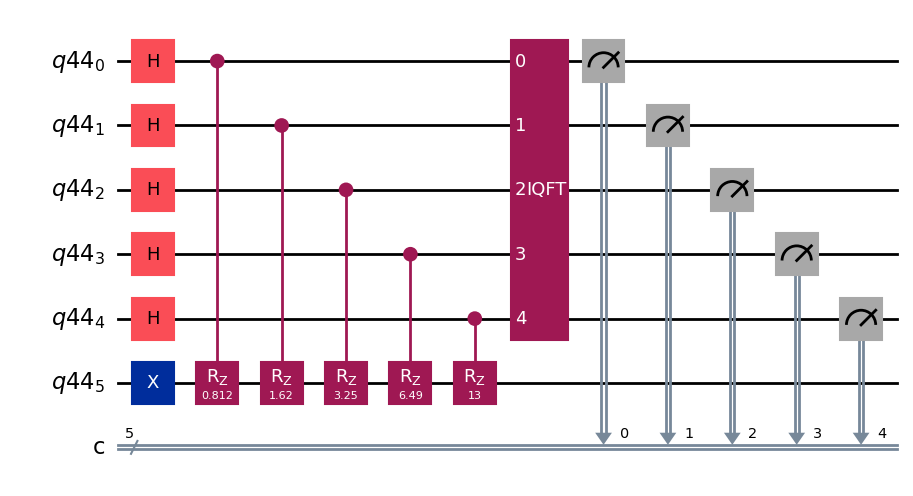

Running on backend: aer_simulator ...
Job ID:  de7d1b9e-b6c3-45eb-ba6d-b74d660d933b
Waiting for job to complete...
Phase Estimation Result: 
{'00010': 1004, '00100': 3, '00011': 5, '00001': 5, '00000': 3, '11110': 1, '01001': 1, '00111': 1, '01110': 1}


qiskit_runtime_service.backends:WARNING:2025-11-16 16:17:29,004: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:17:32,279: Using instance: open-instance, plan: open


Backend selected: ibm_fez


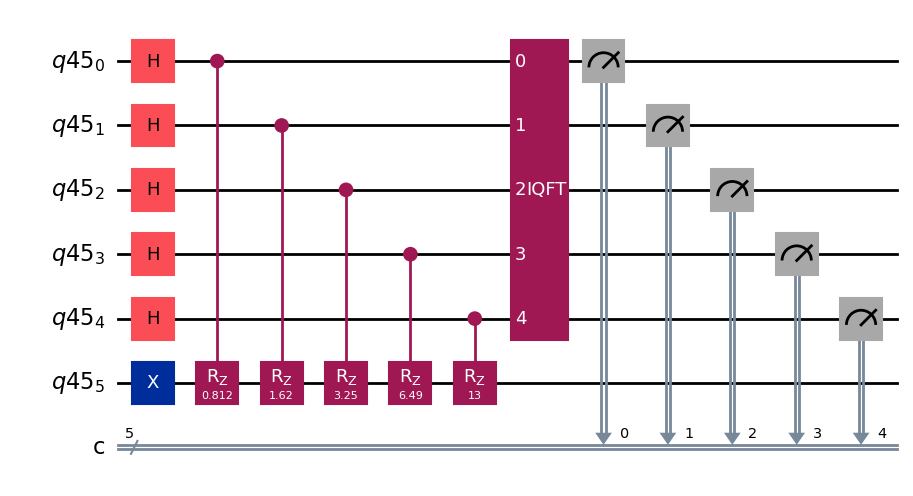

Running on backend: ibm_fez ...
Job ID:  d4cqni9lag1s73bmel5g
Waiting for job to complete...
Phase Estimation Result: 
{'00010': 714, '10010': 19, '00000': 47, '01101': 2, '11010': 14, '10110': 6, '00100': 9, '01010': 22, '10011': 16, '01111': 2, '01110': 2, '00011': 63, '01001': 1, '00001': 5, '01011': 6, '00110': 16, '11110': 17, '11011': 10, '10001': 4, '00111': 5, '11100': 6, '11101': 7, '01000': 4, '11111': 5, '10000': 7, '00101': 3, '10100': 3, '10101': 3, '10111': 3, '11001': 1, '11000': 1, '01100': 1}


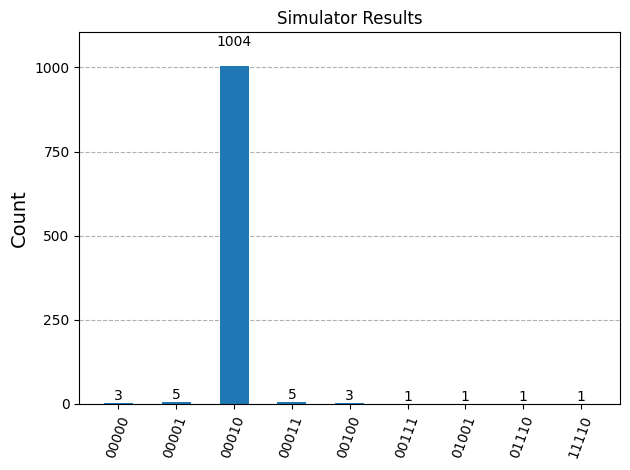

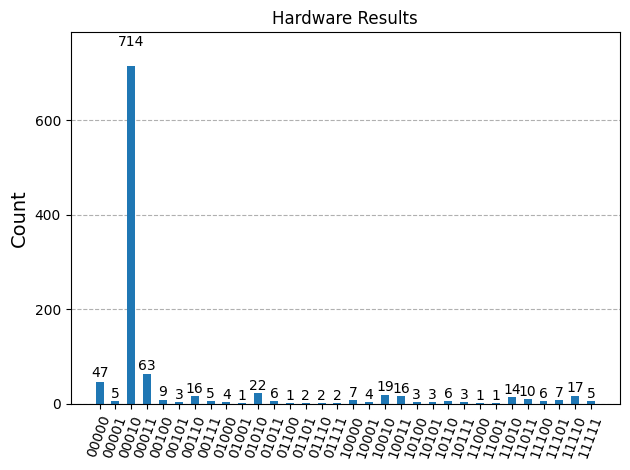

In [ ]:
service = QiskitRuntimeService()

# 2. Find the least-busy REAL quantum device
backend_sim = AerSimulator()
print(f"Backend selected: {backend_sim.name}")
sim_counts = PhaseEstimation(5, 0.1292, backend_sim)
backend = service.least_busy(simulator=False, operational=True)
print(f"Backend selected: {backend.name}")
# 3. Transpile your circuit for that specific backend
phase = 0.1292
qpu_counts = PhaseEstimation(5, phase, backend)
if sim_counts:
    plot_histogram(sim_counts, title=f"Simulator Results")
if qpu_counts:
    plot_histogram(qpu_counts, title=f"Hardware Results")
plt.show()


>We are getting the correct binary representation of the specified angle upto the given no of bits with the max probability. We are also getting incorrect results even in the classical simulator as RZ gate is an approximate gate and may cause multiple representations to occur.

## Grover's Algorithm ##
>This algorithm was challenging to implement. For a single target we can use a single inverting operator that checks the representation of the input state and applies a multicontrol gate based on the target state to flip the output state. However in the case of multiple such targets we would need to append all such oracles together. To invert the output state I kept it in the |-> state. Appying a not to it inverts the |input>|output> state as a whole. The single target oracle must allso be kept unitary to be converted to a gate and thus the input state that was converted to |111...> to implement the mcx easily must reversibly be converted back to its original state by again applying the NOT gates.

In [ ]:
def SingleOracle(n, target):
    oracle_qc = QuantumCircuit(n+1)
    binary_num = format(target, f'0{n}b')[::-1]
    for i in range(n):
        if binary_num[i] == '0':
            oracle_qc.x(i) #Convert the input state from whatever to having 1's at all those places where the target bit has 0. 
    oracle_qc.mcx(list(range(n)), n)
    for i in range(n):
        if binary_num[i] == '0':
            oracle_qc.x(i) #Revert the input state back to original
    return oracle_qc.to_gate() #requires oracle_qc to be unitary

In [ ]:
def MultiOracle(n, targets):
    qc = QuantumCircuit(n+1)
    for target in targets:
        if(target > 2**n - 1):
            print("Target number exceeds the range for n qubits.")
            exit()
        qc.append(SingleOracle(n, target), range(n+1))
    return qc.to_gate()


In [ ]:
def Grover_gate(n, targets):
    qc = QuantumCircuit(n+1)
    qc.append(MultiOracle(n, targets), range(n+1))
    qc.h(range(n))
    qc.x(range(n))
    qc.mcx(list(range(n)), n) #Again the diffusion operator
    qc.x(range(n))
    qc.h(range(n))
    return qc.to_gate()

>You can add your own targets to search for them when prompted for an input

qiskit_runtime_service.__init__:WARNING:2025-11-16 15:54:23,159: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Using AerSimulator (ideal, noise-free)
Number of Grover iterations: 1
Searching for targets: [3, 4]

Running on backend: aer_simulator
Circuit depth before transpilation: 4
Circuit depth after transpilation: 8
Circuit contains 3 two-qubit gates

Job ID: c3f7d3d4-65be-4fd1-bc0d-57ccd055eb93
Waiting for job to complete...

GROVER'S SEARCH RESULTS
Top 10 measured states:
  |011> (decimal  3): 2071 counts ( 50.6%) ⭐ TARGET
  |100> (decimal  4): 2025 counts ( 49.4%) ⭐ TARGET

Total target state probability: 100.0%
Ideal (noise-free) for each would be: ~50.0%


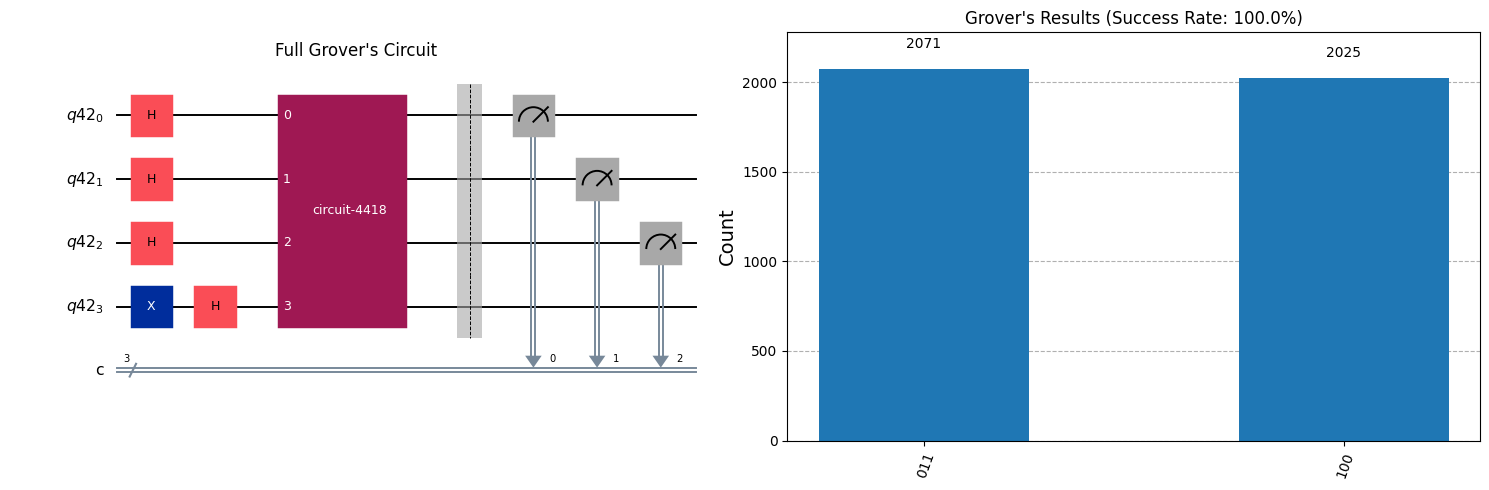

qiskit_runtime_service.backends:WARNING:2025-11-16 15:54:31,384: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 15:54:34,827: Using instance: open-instance, plan: open


Using real hardware: ibm_fez
Number of Grover iterations: 1
Searching for targets: [3, 4]

Running on backend: ibm_fez
Circuit depth before transpilation: 4
Circuit depth after transpilation: 213
Circuit contains 54 two-qubit gates

Job ID: d4cqcrvnmdfs73af3rag
Waiting for job to complete...

GROVER'S SEARCH RESULTS
Top 10 measured states:
  |100> (decimal  4): 1506 counts ( 36.8%) ⭐ TARGET
  |011> (decimal  3):  978 counts ( 23.9%) ⭐ TARGET
  |000> (decimal  0):  337 counts (  8.2%) 
  |001> (decimal  1):  301 counts (  7.3%) 
  |111> (decimal  7):  277 counts (  6.8%) 
  |010> (decimal  2):  259 counts (  6.3%) 
  |110> (decimal  6):  233 counts (  5.7%) 
  |101> (decimal  5):  205 counts (  5.0%) 

Total target state probability: 60.6%
Ideal (noise-free) for each would be: ~50.0%


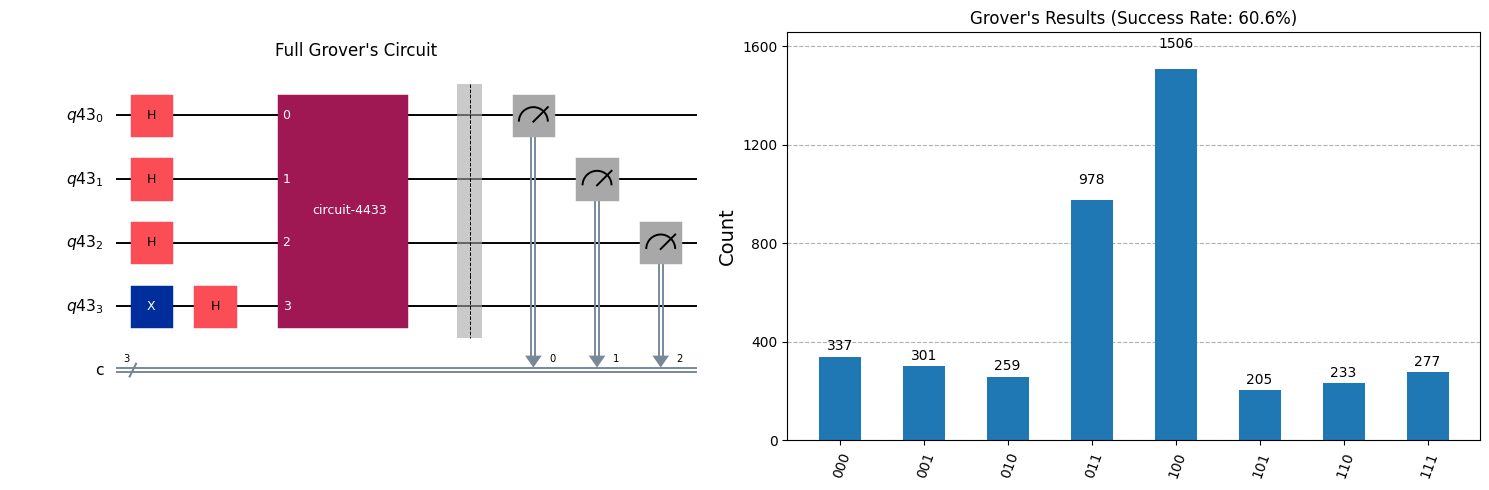

{'101': 205,
 '100': 1506,
 '001': 301,
 '011': 978,
 '111': 277,
 '000': 337,
 '010': 259,
 '110': 233}

In [157]:
def Grover_Search(n, backend):
    q = QuantumRegister(n+1)
    c = ClassicalRegister(n, name='c')
    qc = QuantumCircuit(q, c)

    # Initialization
    qc.h(range(n))
    qc.x(n)
    qc.h(n)
    
    targets = list(map(int, input(f"Enter target numbers between {0} and {2**n - 1} separated by spaces: ").split()))

    N = 2**n
    M = len(targets)
    iterations = int(np.floor((np.pi / 4) * np.sqrt(N / M))) #Number of Grover iterations
    if iterations == 0: 
        iterations = 1
    
    print(f"Number of Grover iterations: {iterations}")
    print(f"Searching for targets: {targets}")
    
    # Grover iterations
    for i in range(iterations):
        qc.append(Grover_gate(n, targets), range(n+1))
    
    qc.barrier()
    qc.measure(range(n), range(n))
    
    print(f"\nRunning on backend: {backend.name}")
    print(f"Circuit depth before transpilation: {qc.depth()}")
    
    # Transpile with optimization
    transpiled_qc = transpile(qc, backend, optimization_level=3)
    print(f"Circuit depth after transpilation: {transpiled_qc.depth()}")
    print(f"Circuit contains {transpiled_qc.num_nonlocal_gates()} two-qubit gates")
    
    sampler = SamplerV2(mode=backend)
    job = sampler.run([transpiled_qc], shots=4096)
    print(f"\nJob ID: {job.job_id()}")
    print("Waiting for job to complete...")
    
    pub_result = job.result()[0]
    res = pub_result.data.c.get_counts()
    
    print("\n" + "="*50)
    print("GROVER'S SEARCH RESULTS")
    print("="*50)
    print(f"Top 10 measured states:")
    for state, count in sorted(res.items(), key=lambda x: x[1], reverse=True)[:10]:
        decimal = int(state, 2)
        is_target = "⭐ TARGET" if decimal in targets else ""
        print(f"  |{state}> (decimal {decimal:2d}): {count:4d} counts ({100*count/4096:5.1f}%) {is_target}")
    
    # Calculate success rate
    target_counts = sum(res.get(format(t, f'0{n}b'), 0) for t in targets)
    success_rate = 100 * target_counts / 4096
    print(f"\nTotal target state probability: {success_rate:.1f}%")
    print(f"Ideal (noise-free) for each would be: ~{100 * M / N * (1 + np.sin((2*iterations + 1) * np.arcsin(np.sqrt(M/N)))**2):.1f}%")
    
    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Circuit diagram
    qc.draw(output='mpl', fold=-1, ax=ax1)
    ax1.set_title("Full Grover's Circuit")
    
    # Results histogram
    plot_histogram(res, ax=ax2)
    ax2.set_title(f"Grover's Results (Success Rate: {success_rate:.1f}%)")
    
    plt.tight_layout()
    plt.show()
    
    return res

service = QiskitRuntimeService()


backend_sim = AerSimulator()
print("Using AerSimulator (ideal, noise-free)")
Grover_Search(3, backend_sim)

backend = service.least_busy(simulator=False, operational=True)
print(f"Using real hardware: {backend.name}")

Grover_Search(3, backend)

>The Simulator works well for the above algorithm proving that our algorithm and circuitry is correct. However using multiqubit gates such as mcx made the results turn out really bad on some runs on quantum hardware. As the circuit depth increased with more number of bits, the answers were pretty off and not representative of what they should be resulting in almost an equal probability of each answer.

## Simon's Problem ##
>It was the most difficult to implement and required researching multiple sources to identify how to implement multiple parts of the algorithm. First the development of an oracle that can, without loss of generality, create a 2-1 function which is unique across all choices of a secret string was very difficut. Initially I used an oracle that gave an output 0 whenever s had an ON bit. This gave us a 2-1 function however it was not unique and did not give results which satisfied for just that string but which satisfied the equations for all the secret strings. My current oracle gives a much better function whose logic I will explain below.

>Another part was the classical algo to find the string s from the given equations and to ensure that the equations obtained were linearly independent. I used a numpy library to do the latter which relies on finding the rank of the equations matrix. For the linear equations part also I could have used the same library however, there was a slight modification in it as now we are not talking about addition and subtraction but we are doing so modulo 2. I used AI for some help in this part.

### Creating the oracle ###
> The function here is equivalent to: for ON positions other than pivot, output is equal to XOR of input at pivot pos and at that pos. At the pivot point i.e the first ON bit in s and other OFF positions of s, output bit is same as input bit. For most strings it seems to give a unique output however I am unable to prove this feature of it.

In [ ]:
def create_simon_oracle(n, secret_string):
    oracle = QuantumCircuit(2*n, name=f'Oracle_s={secret_string}')
    
    # Convert secret string to list of integers
    s = [int(bit) for bit in secret_string]
    
    pivot = s.index(1)
    for k in range(n):
        if k!=pivot and s[k]==1:
            oracle.cx(pivot, n+k)
    
    for i in range(n):
        if i!=pivot:
            oracle.cx(i, n+i) 
                
    return oracle.to_gate()


def simon_circuit(n, oracle):
    input_reg = QuantumRegister(n, 'input')
    output_reg = QuantumRegister(n, 'output')
    c = ClassicalRegister(n, 'c')
    qc = QuantumCircuit(input_reg, output_reg, c)
    
    # Step 1: Apply Hadamard to input register
    qc.h(input_reg)
    qc.barrier(label='After H')
    
    # Step 2: Apply oracle
    qc.append(oracle, range(2*n))
    qc.barrier(label='After Oracle')
    
    qc.h(input_reg)
    qc.barrier(label='After H')
    
    qc.measure(input_reg, c)
    
    return qc


### Classical Algorithms ###

In [158]:
def solve_linear_system(equations, n):

    # Convert strings to numpy array
    A = np.array([[int(bit) for bit in eq] for eq in equations])
    
    # Perform Gaussian elimination over GF(2)
    matrix = A.copy()
    rows, cols = matrix.shape
    
    # Convert to reduced row echelon form (mod 2)
    pivot_row = 0
    for col in range(cols):
        # Find pivot
        pivot_found = False
        for row in range(pivot_row, rows):
            if matrix[row, col] == 1:
                # Swap rows
                matrix[[pivot_row, row]] = matrix[[row, pivot_row]]
                pivot_found = True
                break
        
        if not pivot_found:
            continue
        
        # Eliminate
        for row in range(rows):
            if row != pivot_row and matrix[row, col] == 1:
                matrix[row] = (matrix[row] + matrix[pivot_row]) % 2
        
        pivot_row += 1

    for candidate in range(1, 2**n):
        s = [int(bit) for bit in format(candidate, f'0{n}b')]
        # Check if s is orthogonal to all equations
        valid = True
        for eq in equations:
            eq_bits = [int(bit) for bit in eq]
            if sum(s[i] * eq_bits[i] for i in range(n)) % 2 != 0:
                valid = False
                break
        if valid:
            return ''.join(map(str, s))
    
    return '0' * n  # If all zeros, function is one-to-one


def is_linear_combination(target_array, basis_arrays, tolerance=1e-10):
    # Stack basis arrays into a matrix
    A = np.column_stack(basis_arrays)
    
    # Solve the linear system A * x = target_array
    try:
        coeffs, residuals, rank, s = np.linalg.lstsq(A, target_array, rcond=None)
        if residuals.size == 0:
            # If there are no residuals, check if the solution is exact
            return np.allclose(A @ coeffs, target_array, atol=tolerance)
        return residuals[0] < tolerance
    except np.linalg.LinAlgError:
        return False


def gaussian_elimination_mod2(vectors):
    matrix = []
    pivot_indices = []
    
    for vec in vectors:
        if not isinstance(vec, np.ndarray):
            vec = np.array(vec) # Ensure it's an np array
            
        vec_temp = np.copy(vec)
        
        # Reduce this new vector against the existing matrix rows
        for i in range(len(matrix)):
            pivot = pivot_indices[i]
            # Check if pivot is within bounds of vec_temp
            if pivot < len(vec_temp) and vec_temp[pivot] == 1:
                vec_temp = (vec_temp + matrix[i]) % 2 # XOR
        
        # Find the pivot of the reduced vector
        new_pivot_search = np.where(vec_temp == 1)[0]
        
        if len(new_pivot_search) > 0:
            # This is a new independent vector
            new_pivot = new_pivot_search[0]
            matrix.append(vec_temp)
            pivot_indices.append(new_pivot)
            
            # Sort the matrix/pivots to maintain row-echelon property
            # This is crucial for the check_linear_dependence function
            sorted_indices = np.argsort(pivot_indices)
            matrix = [matrix[i] for i in sorted_indices]
            pivot_indices = [pivot_indices[i] for i in sorted_indices]
    
    return matrix

def check_linear_dependence(new_vec, basis_vectors):

    echelon_basis = gaussian_elimination_mod2(basis_vectors)
    
    vec_temp = np.copy(new_vec)
    
    # Iterate through the (now correct) echelon basis vectors
    for basis_row in echelon_basis:
        # Find the pivot (first '1') of the basis row
        pivot_search = np.where(basis_row == 1)[0]
        if len(pivot_search) == 0:
            continue # This row is all zeros
            
        pivot = pivot_search[0]
        
        # If our vector has a '1' at that pivot, XOR the row
        if pivot < len(vec_temp) and vec_temp[pivot] == 1:
            vec_temp = (vec_temp + basis_row) % 2
            
    # After checking all basis rows, see if our vector is all zeros
    is_dependent = not np.any(vec_temp)
    
    return is_dependent

### Iterating and finding n-1 linearly independent vectors to solve for s ###


In [159]:
def main_stuff(oracle, backend, secret_string, n):
    independent_vectors = []  # List of linearly independent bit strings
    all_measured = set()  # All measured strings (for tracking)
    all_counts = {}
            
    if(backend.name == 'aer_simulator'):
        print("AER SIMULATOR RESULTS")
    else:
        print(f"QPU RESULTS FROM {backend.name.upper()}")
    iteration = 0
            
    while len(independent_vectors) < n - 1:
        iteration += 1
        qc = simon_circuit(n, oracle)
        transpiled = transpile(qc, backend)
        sampler = SamplerV2(mode=backend)
        job = sampler.run([transpiled], shots=4096)
        pub_result = job.result()[0]
        counts = pub_result.data.c.get_counts()
        

                # Store all counts for visualization
        for bitstring, count in counts.items():
            bitstring = bitstring[::-1]  # Reverse to match qubit order
            all_counts[bitstring] = all_counts.get(bitstring, 0) + count
                
                # Check each measured string for linear independence
        new_vectors_this_iteration = []
        for bitstring in counts.keys():
            bitstring = bitstring[::-1]  # Reverse to match qubit order because the leftmost bit in classical register is most significant bit
            print(bitstring)
            if bitstring == '0'*n:  # Skip all-zeros
                continue
                
            if bitstring in all_measured:  # Already seen this vector
                continue
                
            all_measured.add(bitstring)
                
            # Check if this vector is linearly independent from what we have
            if(len(independent_vectors) == 0):
                independent_vectors.append(np.array(list(bitstring), dtype=int))
                new_vectors_this_iteration.append(bitstring)
                print(f"  Iteration {iteration}: Found independent vector {bitstring} ({len(independent_vectors)}/{n-1})")
                continue
            if not check_linear_dependence(np.array(list(bitstring), dtype=int), independent_vectors):
                independent_vectors.append(np.array(list(bitstring), dtype=int))
                new_vectors_this_iteration.append(bitstring)
                print(f"  Iteration {iteration}: Found independent vector {bitstring} ({len(independent_vectors)}/{n-1})")
                    
                if len(independent_vectors) >= n - 1:
                    break
            
            
        if iteration > 100:  # Safety limit
            print("  Warning: Taking many iterations. Using available vectors.")
            break
        
    print(f"\nCollected {len(independent_vectors)} linearly independent equations:")
    for i, eq in enumerate(independent_vectors, 1):
            # Verify orthogonality with secret string
        dot_product = sum(int(eq[j]) * int(secret_string[j]) for j in range(n)) % 2
        check = "✓" if dot_product == 0 else "✗"
        print(f"  y{i} = {eq}  (y·s = {dot_product} mod 2) {check}")
    
    print("\nSolving system of equations over GF(2)...")
    found_secret = solve_linear_system(independent_vectors, n)
    
    print("\n" + "="*60)
    print("RESULTS")
    print("="*60)
    print(f"Actual secret string:  s = {secret_string}")
    print(f"Found secret string:   s = {found_secret}")
    print(f"Match: {'✓ SUCCESS!' if found_secret == secret_string else '✗ FAILED'}")
    print(f"Total quantum queries: {iteration}")
    print(f"Classical queries needed: O(2^{n}) = {2**(n-1)} average")
    print(f"Speedup: ~{2**(n-1) / iteration:.0f}x")
    print("="*60)
    
    # Visualize measurement distribution
    plot_histogram(all_counts, figsize=(12, 6))
    plt.title(f"Simon's Algorithm Measurements (s={secret_string})")
    plt.tight_layout()
    plt.show()
    

In [160]:
def run_simons_algorithm(n, secret_string, shots=1000):
    print("="*60)
    print(f"SIMON'S ALGORITHM - Finding Secret String")
    print("="*60)
    print(f"Input size: n = {n} qubits")
    print(f"Actual secret string: s = {secret_string}")
    print(f"Search space size: 2^n = {2**n}")
    print()
    
    # Create oracle
    oracle = create_simon_oracle(n, secret_string)
    
    demo_circuit = simon_circuit(n, oracle)
    demo_circuit.draw(output='mpl', fold=-1)
    plt.suptitle(f"Simon's Algorithm Circuit (n={n}, s={secret_string})")
    plt.tight_layout()
    plt.show()
    
    service = QiskitRuntimeService()
    backend_sim = AerSimulator()
    backend = service.least_busy(simulator=False, operational=True)

    main_stuff(oracle, backend_sim, secret_string, n)
    main_stuff(oracle, backend, secret_string, n)


SIMON'S ALGORITHM DEMONSTRATION

This algorithm finds a hidden secret string exponentially
faster than any classical algorithm!


### Example 1: n=3 qubits ###
SIMON'S ALGORITHM - Finding Secret String
Input size: n = 3 qubits
Actual secret string: s = 110
Search space size: 2^n = 8



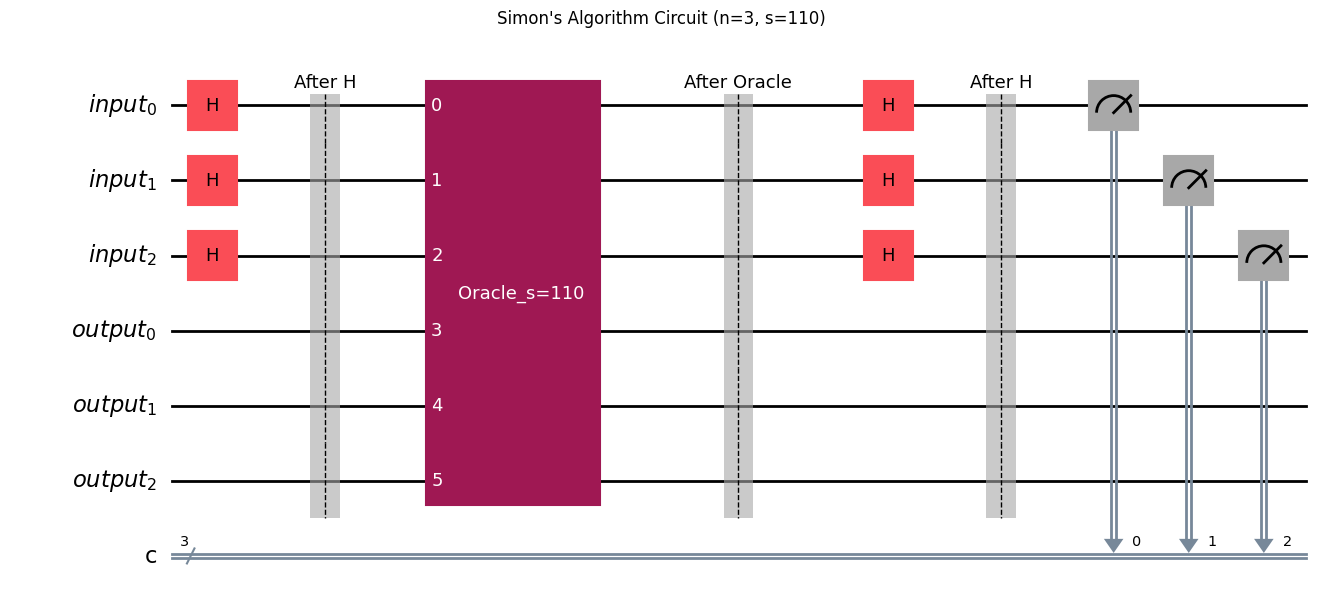

qiskit_runtime_service.__init__:WARNING:2025-11-16 16:14:23,200: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-11-16 16:14:23,859: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:14:26,853: Using instance: open-instance, plan: open


AER SIMULATOR RESULTS
001
  Iteration 1: Found independent vector 001 (1/2)
110
  Iteration 1: Found independent vector 110 (2/2)

Collected 2 linearly independent equations:
  y1 = [0 0 1]  (y·s = 0 mod 2) ✓
  y2 = [1 1 0]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 110
Found secret string:   s = 110
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^3) = 4 average
Speedup: ~4x


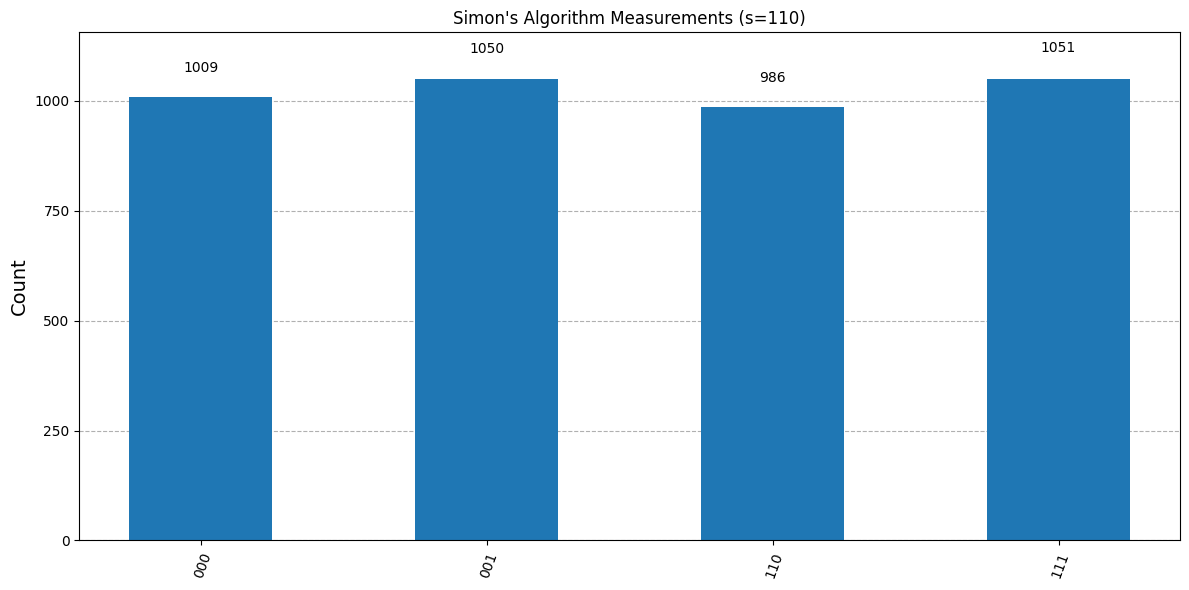

QPU RESULTS FROM IBM_FEZ
110
  Iteration 1: Found independent vector 110 (1/2)
111
  Iteration 1: Found independent vector 111 (2/2)

Collected 2 linearly independent equations:
  y1 = [1 1 0]  (y·s = 0 mod 2) ✓
  y2 = [1 1 1]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 110
Found secret string:   s = 110
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^3) = 4 average
Speedup: ~4x


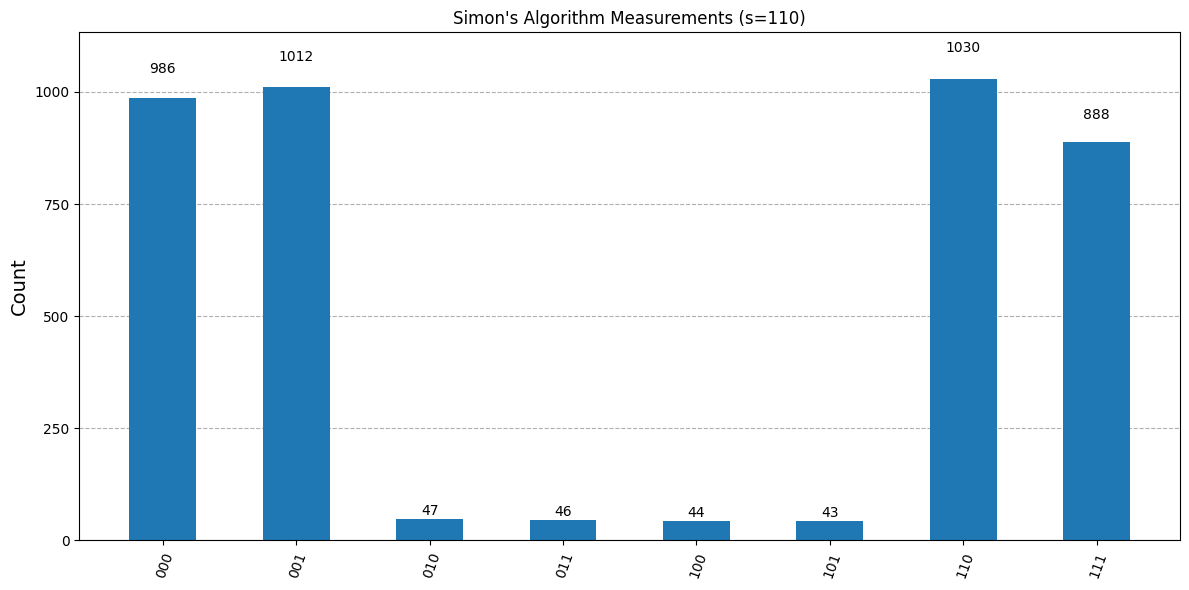



### Example 2: n=4 qubits ###
SIMON'S ALGORITHM - Finding Secret String
Input size: n = 4 qubits
Actual secret string: s = 1010
Search space size: 2^n = 16



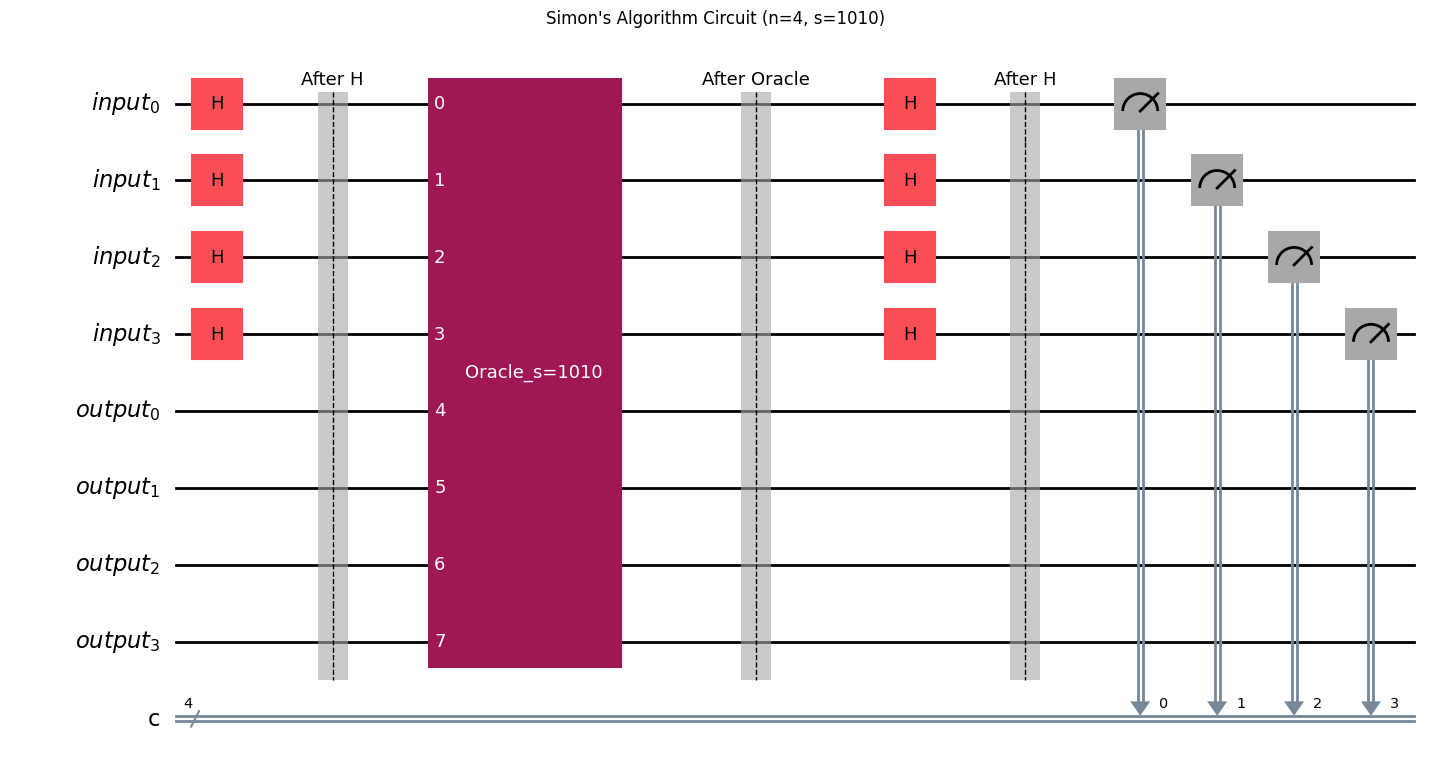

qiskit_runtime_service.__init__:WARNING:2025-11-16 16:14:49,516: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-11-16 16:14:50,139: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:14:53,506: Using instance: open-instance, plan: open


AER SIMULATOR RESULTS
1010
  Iteration 1: Found independent vector 1010 (1/3)
0100
  Iteration 1: Found independent vector 0100 (2/3)
1011
  Iteration 1: Found independent vector 1011 (3/3)

Collected 3 linearly independent equations:
  y1 = [1 0 1 0]  (y·s = 0 mod 2) ✓
  y2 = [0 1 0 0]  (y·s = 0 mod 2) ✓
  y3 = [1 0 1 1]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 1010
Found secret string:   s = 1010
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^4) = 8 average
Speedup: ~8x


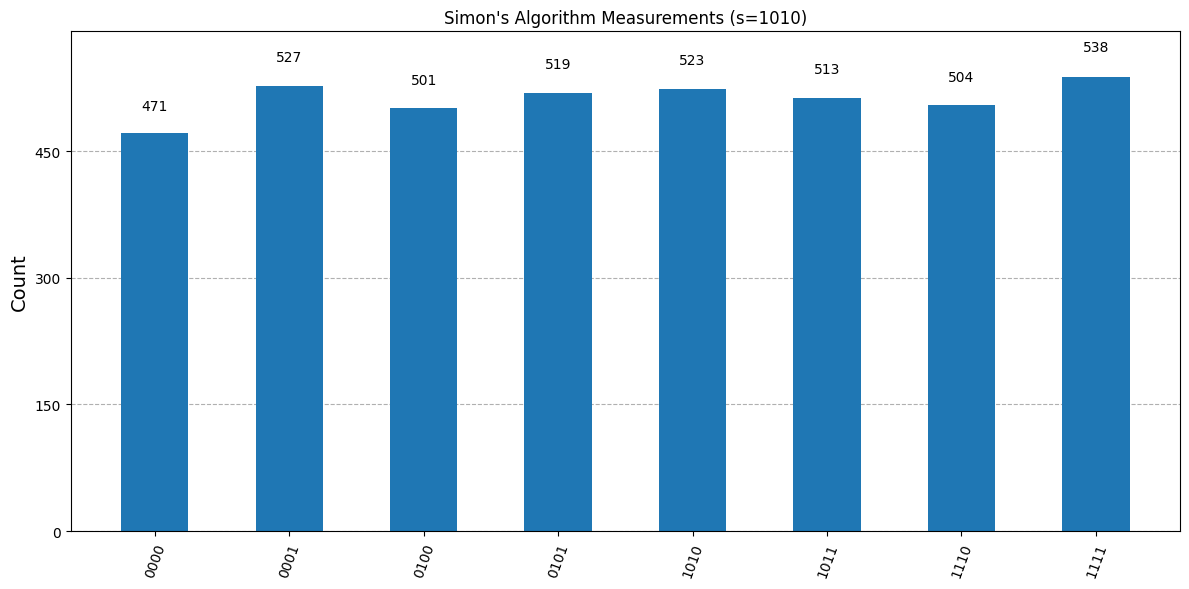

QPU RESULTS FROM IBM_FEZ
0000
0101
  Iteration 1: Found independent vector 0101 (1/3)
1111
  Iteration 1: Found independent vector 1111 (2/3)
1010
0100
  Iteration 1: Found independent vector 0100 (3/3)

Collected 3 linearly independent equations:
  y1 = [0 1 0 1]  (y·s = 0 mod 2) ✓
  y2 = [1 1 1 1]  (y·s = 0 mod 2) ✓
  y3 = [0 1 0 0]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 1010
Found secret string:   s = 1010
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^4) = 8 average
Speedup: ~8x


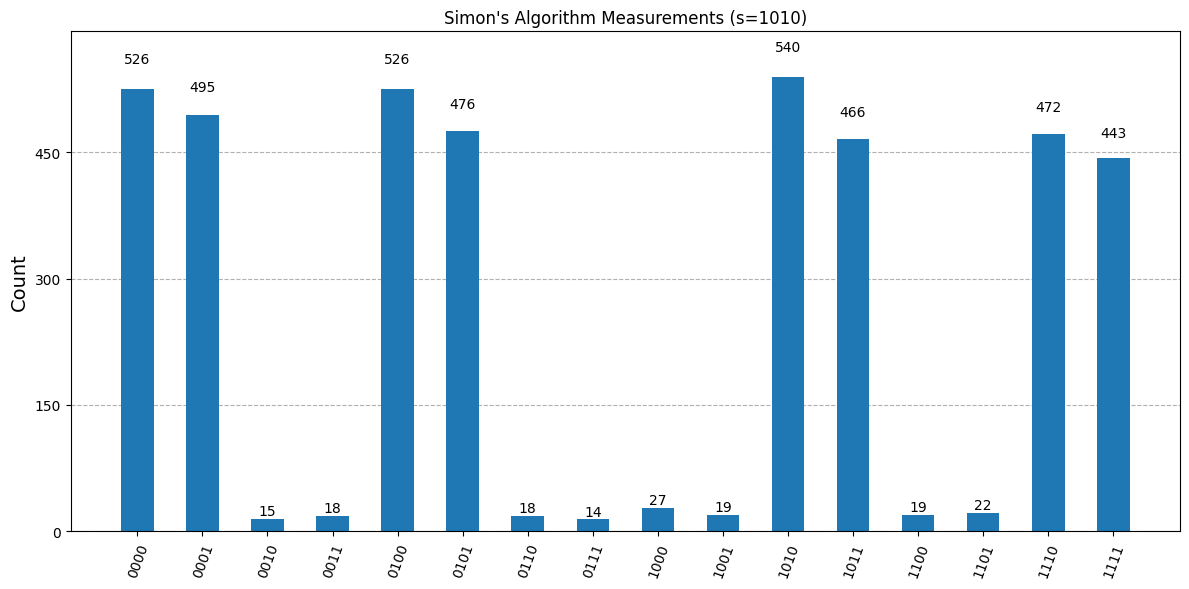



### Example 3: n=4 qubits ###
SIMON'S ALGORITHM - Finding Secret String
Input size: n = 4 qubits
Actual secret string: s = 1101
Search space size: 2^n = 16



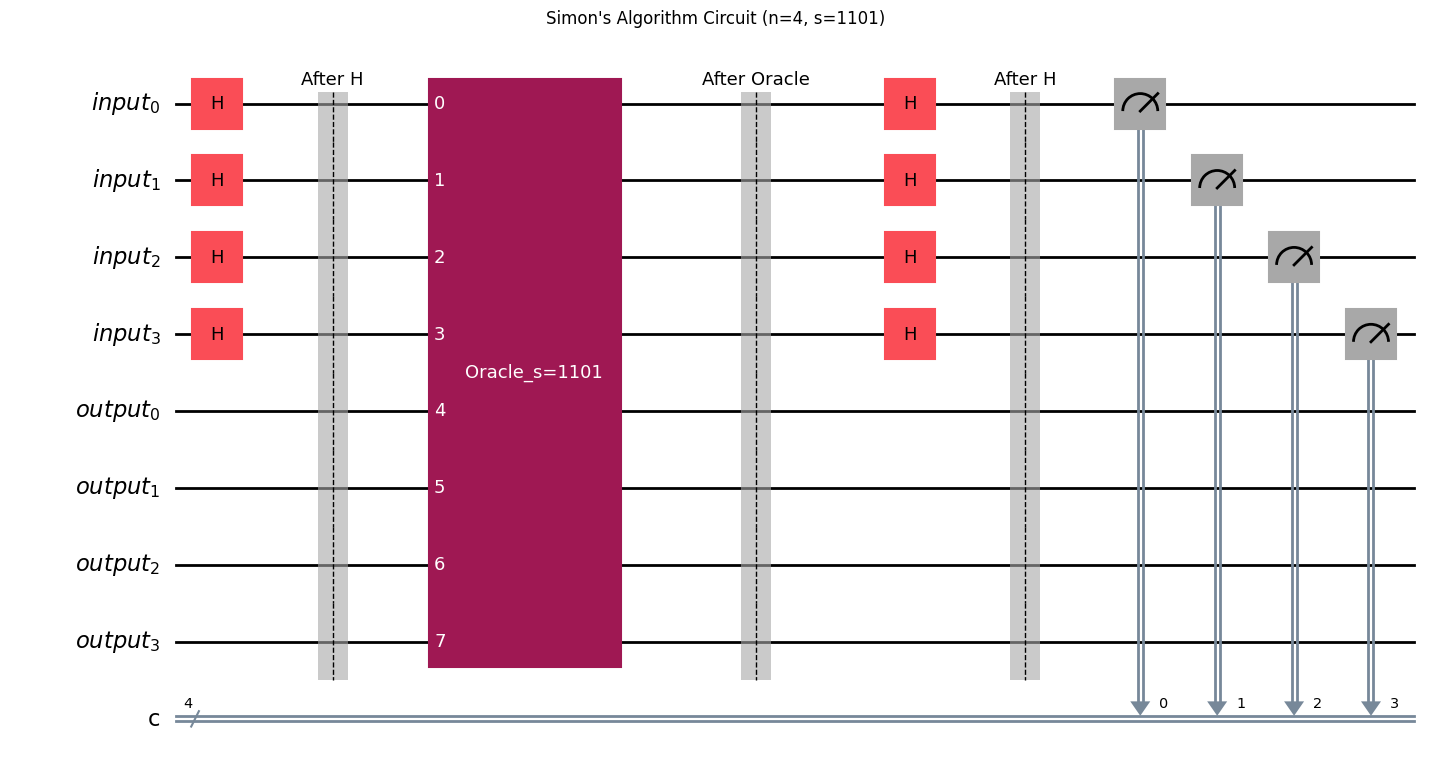

qiskit_runtime_service.__init__:WARNING:2025-11-16 16:15:13,993: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-11-16 16:15:14,710: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-11-16 16:15:19,073: Using instance: open-instance, plan: open


AER SIMULATOR RESULTS
1100
  Iteration 1: Found independent vector 1100 (1/3)
1011
  Iteration 1: Found independent vector 1011 (2/3)
1110
  Iteration 1: Found independent vector 1110 (3/3)

Collected 3 linearly independent equations:
  y1 = [1 1 0 0]  (y·s = 0 mod 2) ✓
  y2 = [1 0 1 1]  (y·s = 0 mod 2) ✓
  y3 = [1 1 1 0]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 1101
Found secret string:   s = 1101
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^4) = 8 average
Speedup: ~8x


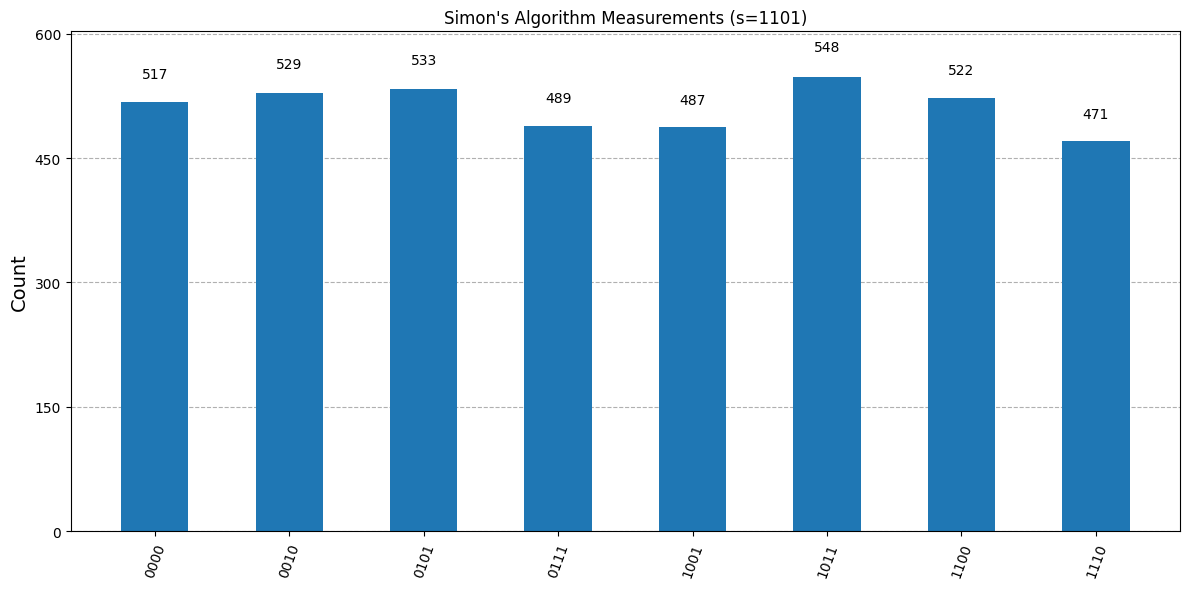

QPU RESULTS FROM IBM_FEZ
1001
  Iteration 1: Found independent vector 1001 (1/3)
0010
  Iteration 1: Found independent vector 0010 (2/3)
1100
  Iteration 1: Found independent vector 1100 (3/3)

Collected 3 linearly independent equations:
  y1 = [1 0 0 1]  (y·s = 0 mod 2) ✓
  y2 = [0 0 1 0]  (y·s = 0 mod 2) ✓
  y3 = [1 1 0 0]  (y·s = 0 mod 2) ✓

Solving system of equations over GF(2)...

RESULTS
Actual secret string:  s = 1101
Found secret string:   s = 1101
Match: ✓ SUCCESS!
Total quantum queries: 1
Classical queries needed: O(2^4) = 8 average
Speedup: ~8x


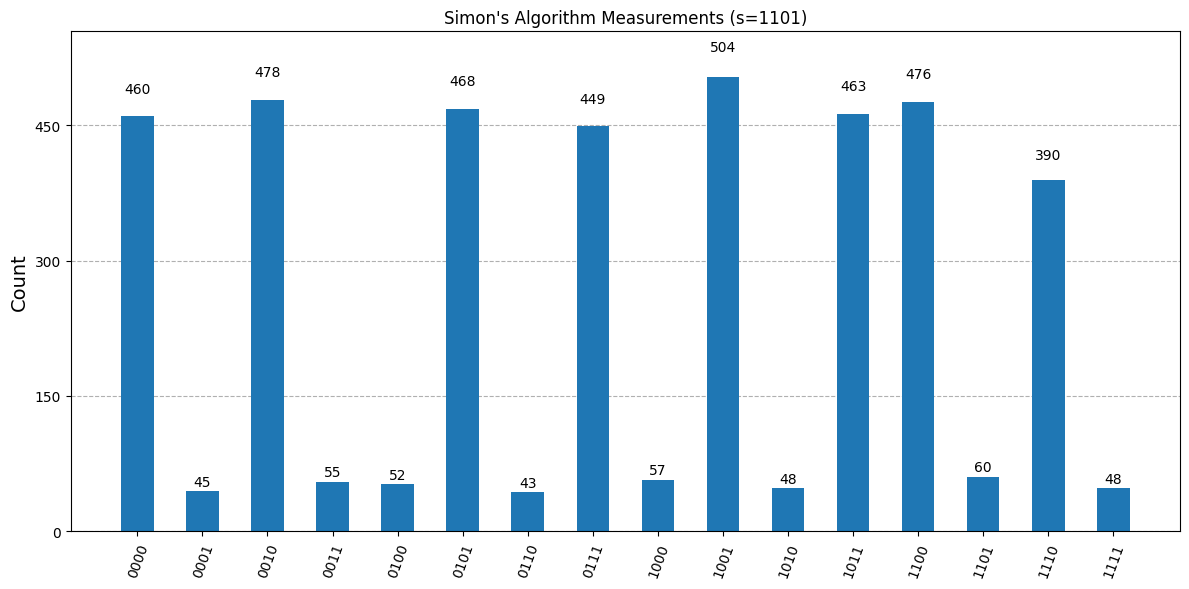

In [161]:
if __name__ == "__main__":  # Run examples of your own and check results
    print("\n" + "="*60)
    print("SIMON'S ALGORITHM DEMONSTRATION")
    print("="*60)
    print("\nThis algorithm finds a hidden secret string exponentially")
    print("faster than any classical algorithm!\n")
        
    # Example 1: Simple case (n=3)
    print("\n### Example 1: n=3 qubits ###")
    n = 3
    secret = "110"
    run_simons_algorithm(n, secret, shots=1000)
    
    # Example 2: Larger case (n=4)
    print("\n\n### Example 2: n=4 qubits ###")
    n = 4
    secret = "1010"
    found = run_simons_algorithm(n, secret, shots=1000)

    print("\n\n### Example 3: n=4 qubits ###")
    n = 4
    secret = "1101"
    found = run_simons_algorithm(n, secret, shots=1000)

### Results ###
Our simon's algorithm does give pretty good results for most of the examples above. Again the actual quantum hardware has some noise but it is quite less noisy than Grover's algorithm.